# 03 · How Much Did the 2020 Lockdown Change Air Quality?

India's national lockdown began on **25 March 2020**. Phases 1 and 2, the strictest period, ran until **3 May**. Traffic, construction and most industry stopped almost overnight, creating a natural experiment.

The obvious approach, comparing April 2020 with April 2019, has a flaw: if 2020 was already cleaner than 2019 *before* the lockdown (different weather, new policies, sensor drift), the simple comparison wrongly credits that difference to the lockdown.

**Method.** For each city:

| | 2019 | 2020 |
|---|---|---|
| Pre-lockdown (1 Jan – 21 Mar) | A | B |
| Lockdown (25 Mar – 3 May) | C | D |

- *Simple change* = D / C − 1
- *Pre-existing gap* = B / A − 1
- **Lockdown effect** = (D / C) ÷ (B / A) − 1

This is a **difference-in-differences** on the ratio scale. It assumes that, without the lockdown, the 2020-vs-2019 gap would have stayed the same from winter into spring. Each window is summarised by its median day. Uncertainty comes from a **weekly block bootstrap**: days are resampled in whole weeks because pollution on neighbouring days is correlated.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from air_quality import config, data, events, lockdown, plots, quality

plots.set_style()
pd.set_option("display.precision", 2)
FIG = config.FIGURES_DIR
TABLES = config.TABLES_DIR
TABLES.mkdir(parents=True, exist_ok=True)

df = data.load_clean()

## 1. What it looks like in one city

Delhi's NO₂ (mainly from traffic), 2020 against 2019:

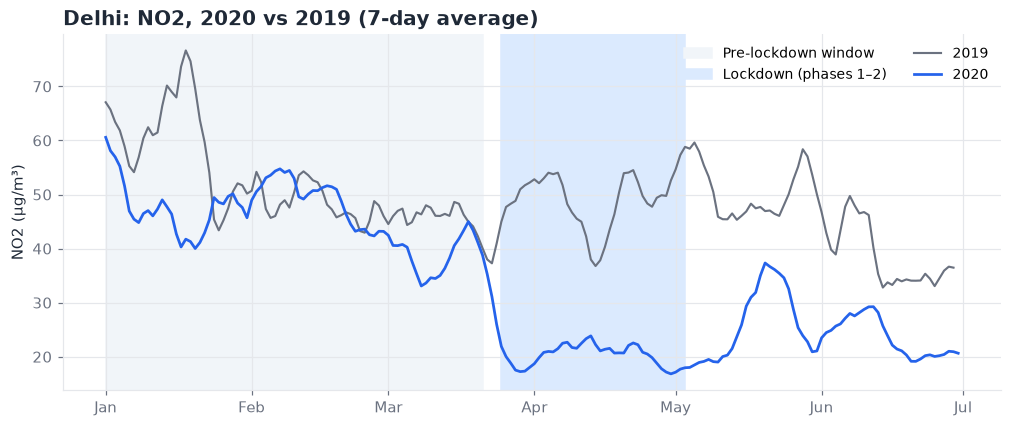

In [2]:
plots.city_timeline(lockdown.daily_comparison(df, "Delhi", "NO2"), "Delhi", "NO2",
                    FIG / "06_delhi_no2_timeline.png");

Before the lockdown, the two years track each other closely. From 25 March, 2020 falls to less than half of 2019 and stays there. It is already dipping in mid-March, as offices and schools began closing and the 22 March "Janata curfew" approached; that's why the pre-lockdown window ends on 21 March.

## 2. All cities, five pollutants

In [3]:
POLLUTANTS = ["PM2.5", "NO2", "CO", "SO2", "O3"]
effects = {p: lockdown.lockdown_effect(df, p) for p in POLLUTANTS}
summaries = {p: lockdown.summarise(effects[p]) for p in POLLUTANTS}

summary_table = pd.DataFrame(summaries).T[[
    "n_cities", "typical_raw_change", "typical_pre_trend", "typical_adjusted_change",
    "ci_low", "ci_high", "cities_clear_decrease", "cities_clear_increase"]]
summary_table.to_csv(TABLES / "lockdown_summary.csv")
pct = ["typical_raw_change", "typical_pre_trend", "typical_adjusted_change", "ci_low", "ci_high"]
summary_table.assign(**{c: (summary_table[c].astype(float) * 100).round(0) for c in pct})

,n_cities,typical_raw_change,typical_pre_trend,typical_adjusted_change,ci_low,ci_high,cities_clear_decrease,cities_clear_increase
PM2.5,15.0,-45.0,-17.0,-33.0,-47.0,-17.0,8.0,0.0
NO2,12.0,-45.0,-10.0,-39.0,-55.0,-16.0,6.0,1.0
CO,11.0,-34.0,-5.0,-31.0,-56.0,5.0,7.0,1.0
SO2,13.0,11.0,-14.0,29.0,-10.0,95.0,1.0,3.0
O3,13.0,8.0,-7.0,16.0,-8.0,49.0,4.0,3.0


*"Typical"* is the geometric mean across cities, the standard way to average percentage changes (a halving and a doubling cancel out). Cities whose 2019 baseline was not comparable are excluded; see section 4.

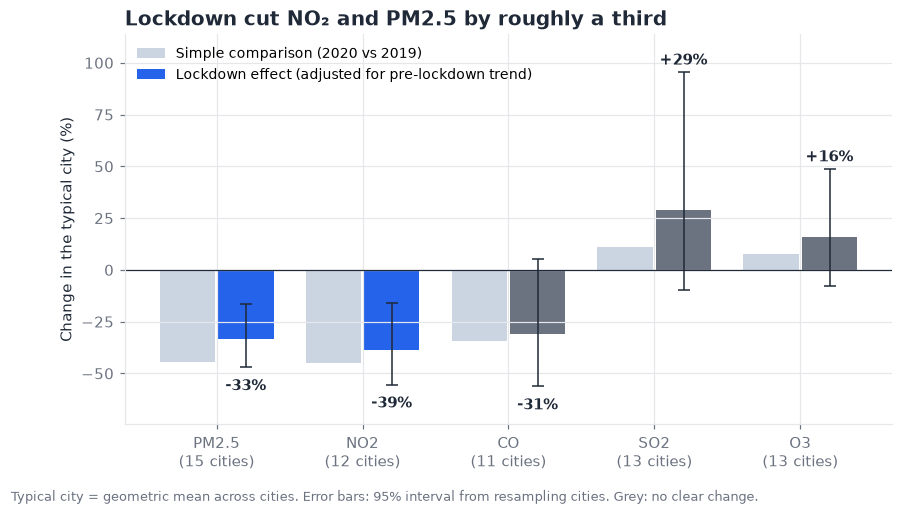

In [4]:
plots.change_overview(summaries, FIG / "03_lockdown_overview.png",
                      title="Lockdown cut NO₂ and PM2.5 by roughly a third");

**Findings**

- **NO₂ fell by about 39%** in the typical city (95% interval −55% to −16%). NO₂ comes mainly from vehicle exhausts, so it fell furthest, as expected with traffic halted.
- **PM2.5 fell by about 33%** (−47% to −17%). It fell less than NO₂ because a large share of PM2.5 comes from sources the lockdown didn't stop: dust, household cooking fuel, agricultural burning and pollution blown in from other regions.
- **The simple comparison overstates the effect.** Early 2020 was already cleaner than early 2019 in many cities, so a naive April-vs-April comparison gives larger falls than the adjusted estimate.
- **CO probably fell**, but the interval includes zero.
- **SO₂ and ozone show no clear fall.** That is consistent with SO₂ coming mainly from coal power plants, which kept running, and with ozone often rising when NO₂ falls (NO₂ normally helps remove ozone in cities). This analysis can't prove those mechanisms; they are the standard explanations.

## 3. City by city

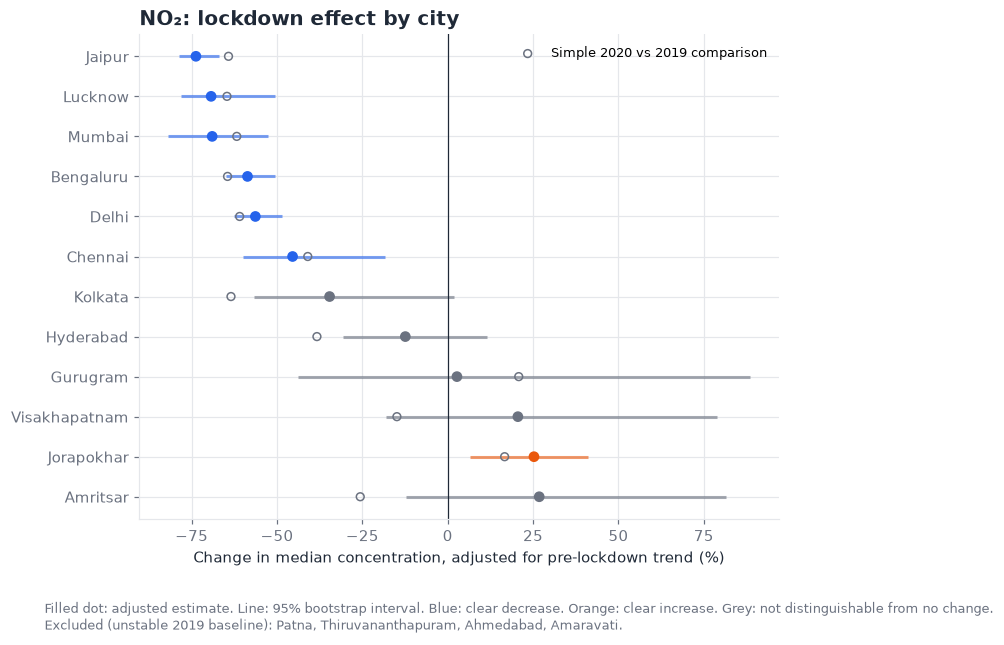

In [5]:
plots.city_effects(effects["NO2"], "NO₂", FIG / "04_lockdown_no2_by_city.png");

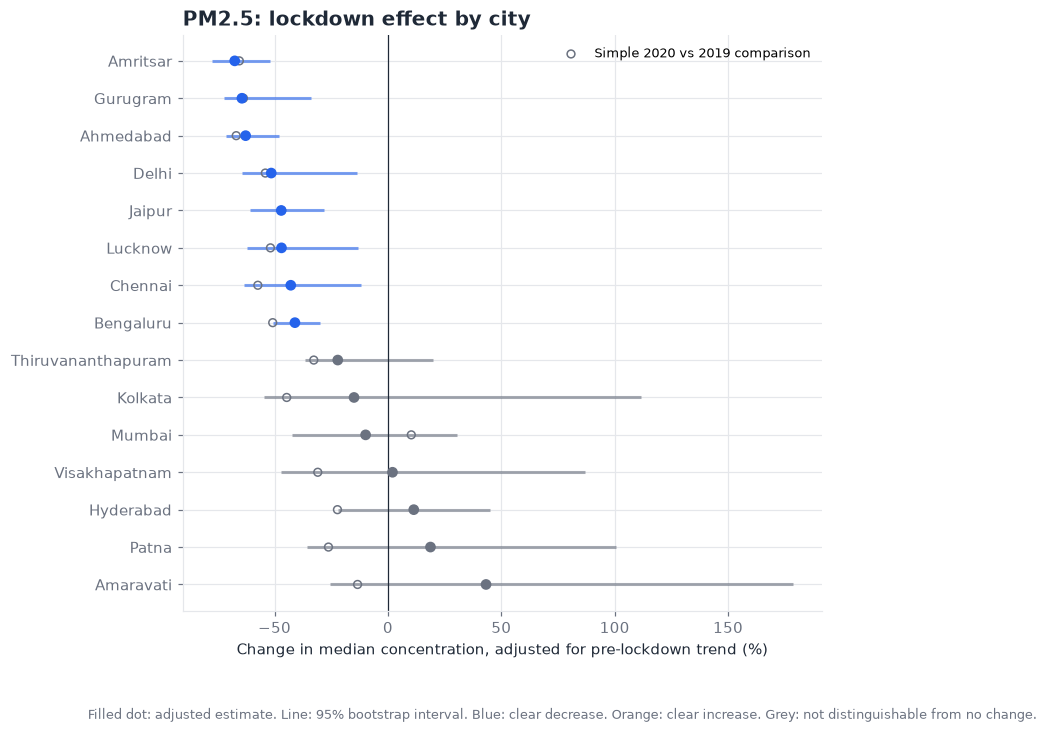

In [6]:
plots.city_effects(effects["PM2.5"], "PM2.5", FIG / "05_lockdown_pm25_by_city.png");

In [7]:
cols = ["City", "Region", "raw_change", "pre_trend", "adjusted_change", "ci_low", "ci_high",
        "stable_baseline"]
for p in POLLUTANTS:
    effects[p].to_csv(TABLES / f"lockdown_by_city_{p.replace('.', '')}.csv", index=False)
effects["NO2"][cols]

,City,Region,raw_change,pre_trend,adjusted_change,ci_low,ci_high,stable_baseline
0,Jaipur,North,-0.64,0.36,-0.74,-0.79,-0.67,True
1,Lucknow,North,-0.65,0.15,-0.69,-0.78,-0.51,True
2,Mumbai,West,-0.62,0.23,-0.69,-0.82,-0.53,True
3,Patna,East,-0.43,0.62,-0.65,-0.78,0.37,False
4,Bengaluru,South,-0.64,-0.14,-0.59,-0.65,-0.51,True
5,Delhi,North,-0.61,-0.11,-0.56,-0.63,-0.48,True
6,Thiruvananthapuram,South,0.46,1.96,-0.50,-0.60,-0.35,False
7,Chennai,South,-0.41,0.08,-0.45,-0.60,-0.18,True
8,Kolkata,East,-0.63,-0.44,-0.35,-0.57,0.02,True
9,Ahmedabad,West,-0.68,-0.56,-0.27,-0.60,0.21,False


The large cities with the most traffic (Jaipur, Lucknow, Mumbai, Bengaluru, Delhi, Chennai) show clear NO₂ decreases of 45-75%. Smaller industrial sites such as Jorapokhar, in Jharkhand's coal belt, show no fall or even a rise, consistent with mining and heavy industry continuing.

## 4. How robust is the result?

Every analysis involves choices. A result worth reporting shouldn't depend on one arbitrary choice, so the headline estimate is recalculated under alternatives:

In [8]:
robustness = pd.concat({p: lockdown.sensitivity(df, p) for p in ["PM2.5", "NO2"]})
robustness.to_csv(TABLES / "lockdown_sensitivity.csv")
pct_cols = ["Simple change", "Adjusted change", "95% CI low", "95% CI high"]
robustness.assign(**{c: (robustness[c] * 100).round(0) for c in pct_cols})

Cities  \
      Scenario                                                     
PM2.5 Main analysis (median, 80% coverage, ±50% basel...      15   
      Mean instead of median                                  15   
      Stricter coverage (90%)                                 13   
      Looser coverage (70%)                                   16   
      Stricter baseline (±30%)                                10   
      No baseline filter                                      15   
NO2   Main analysis (median, 80% coverage, ±50% basel...      12   
      Mean instead of median                                  14   
      Stricter coverage (90%)                                 11   
      Looser coverage (70%)                                   12   
      Stricter baseline (±30%)                                 9   
      No baseline filter                                      16   

                                                          Simple change  \
      Scenario                                                            
PM2.5 Main analysis (median, 80% coverage, ±50% basel...          -45.0   
      Mean instead of median                                      -43.0   
      Stricter coverage (90%)                                     -41.0   
      Looser coverage (70%)                                       -43.0   
      Stricter baseline (±30%)                                    -51.0   
      No baseline filter                                          -45.0   
NO2   Main analysis (median, 80% coverage, ±50% basel...          -45.0   
      Mean instead of median                                      -47.0   
      Stricter coverage (90%)                                     -46.0   
      Looser coverage (70%)                                       -45.0   
      Stricter baseline (±30%)                                    -41.0   
      No baseline filter                                          -44.0   

                                                          Adjusted change  \
      Scenario                                                              
PM2.5 Main analysis (median, 80% coverage, ±50% basel...            -33.0   
      Mean instead of median                                        -27.0   
      Stricter coverage (90%)                                       -29.0   
      Looser coverage (70%)                                         -31.0   
      Stricter baseline (±30%)                                      -48.0   
      No baseline filter                                            -33.0   
NO2   Main analysis (median, 80% coverage, ±50% basel...            -39.0   
      Mean instead of median                                        -37.0   
      Stricter coverage (90%)                                       -43.0   
      Looser coverage (70%)                                         -39.0   
      Stricter baseline (±30%)                                      -38.0   
      No baseline filter                                            -40.0   

                                                          95% CI low  \
      Scenario                                                         
PM2.5 Main analysis (median, 80% coverage, ±50% basel...       -47.0   
      Mean instead of median                                   -41.0   
      Stricter coverage (90%)                                  -43.0   
      Looser coverage (70%)                                    -45.0   
      Stricter baseline (±30%)                                 -57.0   
      No baseline filter                                       -47.0   
NO2   Main analysis (median, 80% coverage, ±50% basel...       -55.0   
      Mean instead of median                                   -53.0   
      Stricter coverage (90%)                                  -58.0   
      Looser coverage (70%)                                    -55.0   
      Stricter baseline (±30%)                                 -57.0   
      No baseline filter               

- The lockdown effect is **negative in every scenario, and its 95% interval excludes zero every time**, for both pollutants. NO₂ is very stable (−37% to −43%). PM2.5 depends more on the choices (−27% to −48%), so the honest headline is *"about a third"*, not a precise percentage.
- Using **means instead of medians** gives a smaller PM2.5 effect. Means are pulled around by a few extreme winter smog days in the pre-lockdown window, which is why the median is the main specification.
- The **±50% baseline rule** excludes cities whose pre-lockdown level changed by more than half between 2019 and 2020 (for NO₂: Patna, Thiruvananthapuram, Ahmedabad, Amaravati). Changes that large usually mean a station or sensor changed, not the air.

## 5. Limitations

- **No weather adjustment.** Rain and wind clean the air. Spring 2020 weather differing from 2019 would affect the estimate. A stronger version would add meteorological data.
- **Two years only.** Using several baseline years (2017-2019) would make the counterfactual more robust, but most cities lack data before 2018.
- **City-level averages** hide variation between monitoring stations within a city.
- **10-16 cities** per pollutant: enough for a clear direction, not for precise national estimates.